# Sistema de Reconhecimento Facial com TensorFlow (Colab + webcam)

**Pipeline**
1. **Detecção**: MTCNN (rede treinada, baseada em TensorFlow) encontra todas as faces do quadro.
2. **Classificação**: MobileNetV2 (transfer learning, TensorFlow/Keras) treinada para identificar cada pessoa.
3. **Inferência**: foto única ou vídeo ao vivo, com várias faces ao mesmo tempo, caixas e nomes desenhados.

**Ordem de execução:** 1 → 2 → 3 (coletar fotos de cada pessoa) → 4 (treinar) → 5 ou 6 (reconhecer).
Permita o acesso à câmera quando o navegador pedir.

In [39]:
!pip -q install mtcnn
import matplotlib.pyplot as plt
import os, cv2, numpy as np, time, shutil
import tensorflow as tf
from tensorflow.keras import layers, models
from mtcnn import MTCNN
from base64 import b64decode
from IPython.display import display, Javascript, clear_output, Image
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow

print("TensorFlow:", tf.__version__)
detector = MTCNN()           # rede de detecção de faces
IMG_SIZE = 160               # tamanho de entrada do classificador
DATASET_DIR = "dataset"
os.makedirs(DATASET_DIR, exist_ok=True)

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


TensorFlow: 2.21.0


## 1. Funções auxiliares (webcam + detecção)

In [40]:
def _decode(data_url):
    raw = b64decode(data_url.split(",")[1])
    return cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)  # BGR

def capture_frames(n=30, interval=0.3):
    """Captura n quadros da webcam (o navegador pede permissão)."""
    display(Javascript('''
    async function capture(n, interval) {
      const video = document.createElement("video");
      document.body.appendChild(video);
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise(r => setTimeout(r, 1500));
      const canvas = document.createElement("canvas");
      canvas.width = video.videoWidth; canvas.height = video.videoHeight;
      const frames = [];
      for (let i = 0; i < n; i++) {
        canvas.getContext("2d").drawImage(video, 0, 0);
        frames.push(canvas.toDataURL("image/jpeg", 0.9));
        await new Promise(r => setTimeout(r, interval * 1000));
      }
      stream.getVideoTracks()[0].stop();
      video.remove();
      return frames;
    }
    '''))
    data = eval_js(f"capture({n}, {interval})")
    return [_decode(d) for d in data]

def detect_faces(frame_bgr, min_conf=0.95):
    """Retorna lista de (x, y, w, h) das faces detectadas."""
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    boxes = []
    for r in detector.detect_faces(rgb):
        if r["confidence"] >= min_conf:
            x, y, w, h = r["box"]
            boxes.append((max(x, 0), max(y, 0), w, h))
    return boxes

def crop_face(frame_bgr, box, margin=0.2):
    x, y, w, h = box
    m = int(margin * max(w, h))
    x1, y1 = max(x - m, 0), max(y - m, 0)
    x2, y2 = min(x + w + m, frame_bgr.shape[1]), min(y + h + m, frame_bgr.shape[0])
    face = frame_bgr[y1:y2, x1:x2]
    return cv2.resize(face, (IMG_SIZE, IMG_SIZE))

## 2. Coletar fotos de cada pessoa
Rode esta célula **uma vez por pessoa** (mude o nome). Mexa um pouco a cabeça durante a captura, com ângulos e expressões diferentes.
Use pelo menos 2 pessoas, ideal ~40 fotos cada. Para ter uma classe extra, você pode coletar uma pessoa chamada `outros`.

In [21]:
NOME = "nanda"      # <-- troque para cada pessoa
N_FOTOS = 40

frames = capture_frames(n=N_FOTOS, interval=0.3)
pasta = os.path.join(DATASET_DIR, NOME)
os.makedirs(pasta, exist_ok=True)

salvas = 0
for i, f in enumerate(frames):
    boxes = detect_faces(f)
    if len(boxes) == 1:   # só salva quando há exatamente uma face
        face = crop_face(f, boxes[0])
        cv2.imwrite(os.path.join(pasta, f"{NOME}_{int(time.time()*1000)}_{i}.jpg"), face)
        salvas += 1
print(f"{salvas} faces salvas em {pasta}")

<IPython.core.display.Javascript object>

38 faces salvas em dataset/nanda


## 3. Conferir o dataset

daniel -> 75 imagens válidas de 75 arquivos
livia -> 70 imagens válidas de 70 arquivos
nanda -> 71 imagens válidas de 71 arquivos


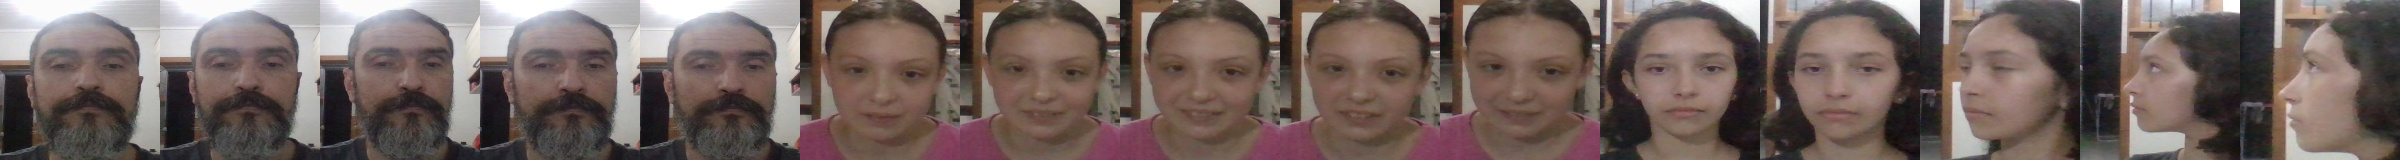

In [41]:
EXTS = (".jpg", ".jpeg", ".png", ".bmp")
amostras = []

for classe in sorted(os.listdir(DATASET_DIR)):
    pasta = os.path.join(DATASET_DIR, classe)
    if not os.path.isdir(pasta):
        continue
    arqs = sorted(os.listdir(pasta))
    validos = 0
    for a in arqs:
        img = cv2.imread(os.path.join(pasta, a)) if a.lower().endswith(EXTS) else None
        if img is None:
            print(f"  [!] arquivo inválido em {classe}: {a}")
            continue
        validos += 1
        if validos <= 5:
            amostras.append(cv2.resize(img, (IMG_SIZE, IMG_SIZE)))
    print(classe, "->", validos, "imagens válidas de", len(arqs), "arquivos")

if amostras:
    cv2_imshow(np.hstack(amostras[:15]))

## 4. Treinar a rede de classificação (MobileNetV2 + transfer learning)

In [42]:
BATCH = 16
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR, validation_split=0.2, subset="training", seed=42,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR, validation_split=0.2, subset="validation", seed=42,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.shuffle(500).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

# Aumento de dados (importante com poucas fotos)
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
])

base = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augment(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = models.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist = model.fit(train_ds, validation_data=val_ds, epochs=12)

# Fine-tuning leve das últimas camadas
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=8)

model.save("face_classifier.keras")
with open("class_names.txt", "w") as f:
    f.write("\n".join(class_names))
print("Modelo salvo.")

Found 216 files belonging to 3 classes.
Using 173 files for training.
Found 216 files belonging to 3 classes.
Using 43 files for validation.
Classes: ['daniel', 'livia', 'nanda']
Epoch 1/12
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 157ms/step - accuracy: 0.5087 - loss: 1.0705 - val_accuracy: 0.7674 - val_loss: 0.6372
Epoch 2/12
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8439 - loss: 0.4857 - val_accuracy: 0.9535 - val_loss: 0.2777
Epoch 3/12
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9364 - loss: 0.2496 - val_accuracy: 0.9535 - val_loss: 0.1822
Epoch 4/12
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9249 - loss: 0.2120 - val_accuracy: 1.0000 - val_loss: 0.1100
Epoch 5/12
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9422 - loss: 0.1615 - val_accuracy: 1.0000 - val_loss: 0.0801
Epoch 6/12
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9942 - loss: 0.0799 - val_accuracy: 1.0000 - val_loss: 0.0629
Epoch 7/12
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accur

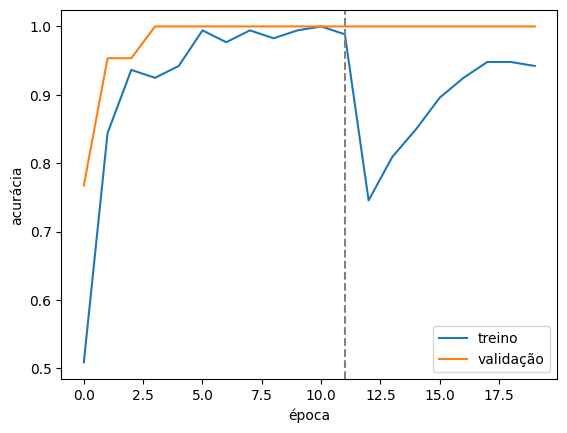

In [43]:
acc = hist.history["accuracy"] + hist2.history["accuracy"]
val = hist.history["val_accuracy"] + hist2.history["val_accuracy"]
plt.plot(acc, label="treino"); plt.plot(val, label="validação")
plt.axvline(len(hist.history["accuracy"]) - 1, ls="--", c="gray")
plt.xlabel("época"); plt.ylabel("acurácia"); plt.legend(); plt.show()

## 5. Reconhecer em uma foto (várias faces)
Posicione uma ou mais pessoas na frente da câmera. Faces com confiança abaixo do limiar aparecem como **Desconhecido**.

<IPython.core.display.Javascript object>

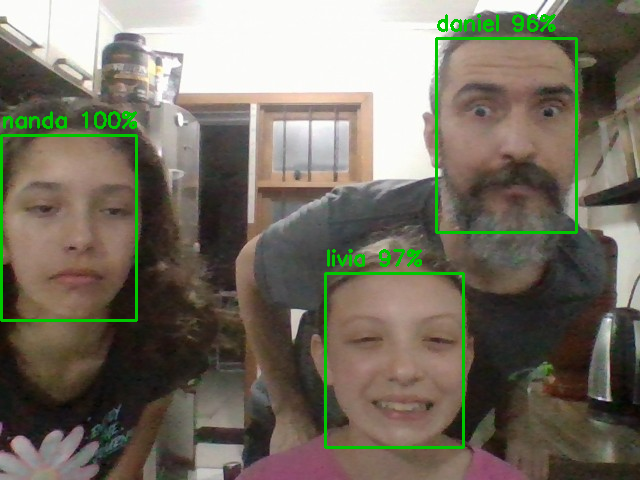

In [34]:
LIMIAR = 0.80

def reconhecer(frame_bgr):
    saida = frame_bgr.copy()
    for box in detect_faces(frame_bgr):
        face = crop_face(frame_bgr, box)
        rgb = cv2.cvtColor(face, cv2.COLOR_BGR2RGB).astype("float32")
        probs = model.predict(rgb[None], verbose=0)[0]
        idx = int(np.argmax(probs)); conf = float(probs[idx])
        nome = class_names[idx] if conf >= LIMIAR else "Desconhecido"
        cor = (0, 200, 0) if nome != "Desconhecido" else (0, 0, 255)
        x, y, w, h = box
        cv2.rectangle(saida, (x, y), (x + w, y + h), cor, 2)
        cv2.putText(saida, f"{nome} {conf*100:.0f}%", (x, max(y - 8, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, cor, 2)
    return saida

frame = capture_frames(n=1, interval=0.1)[0]
cv2_imshow(reconhecer(frame))

## 6. Reconhecimento ao vivo (opcional)
Mostra os quadros da webcam processados em sequência (poucos FPS no Colab, o que é normal).

<IPython.core.display.Javascript object>

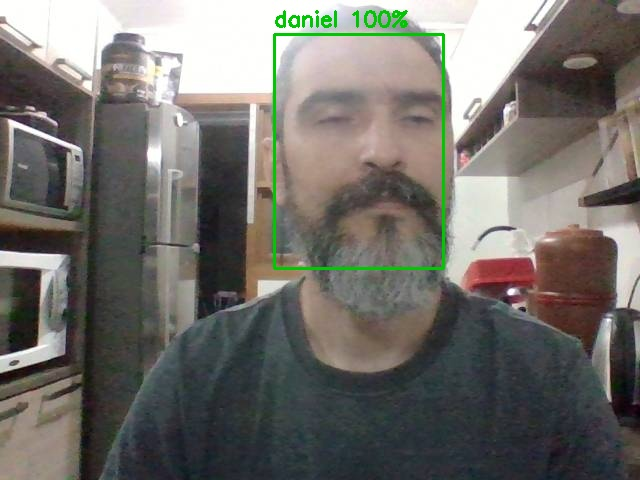

In [36]:
def live_recognition(n_frames=150):
    display(Javascript('''
    window.camInit = async () => {
      const v = document.createElement("video"); v.style.display = "none";
      document.body.appendChild(v);
      v.srcObject = await navigator.mediaDevices.getUserMedia({video: true});
      await v.play();
      window.cam = {v: v, c: document.createElement("canvas")};
      return true;
    };
    window.camFrame = () => {
      const o = window.cam; o.c.width = o.v.videoWidth; o.c.height = o.v.videoHeight;
      o.c.getContext("2d").drawImage(o.v, 0, 0);
      return o.c.toDataURL("image/jpeg", 0.7);
    };
    window.camStop = () => { window.cam.v.srcObject.getTracks().forEach(t => t.stop()); return true; };
    '''))
    eval_js("camInit()")
    handle = None
    try:
        for _ in range(n_frames):
            frame = _decode(eval_js("camFrame()"))
            out = reconhecer(frame)
            _, buf = cv2.imencode(".jpg", out)
            img = Image(data=buf.tobytes())
            if handle is None:
                handle = display(img, display_id=True)
            else:
                handle.update(img)
    finally:
        eval_js("camStop()")

live_recognition(n_frames=100)